
# Statistical Inference and Hypothesis Testing Using Python

**STEM Quantitative Portfolio — Project 2**

## 1. Project Overview

This project demonstrates the application of probability, statistical inference, and hypothesis testing using Python.

Using a synthetic dataset, the project will investigate statistical relationships, estimate population parameters, test research hypotheses, and interpret statistical evidence.

The analysis will cover:

- Probability distributions and sampling.
- Descriptive and inferential statistics.
- Confidence intervals.
- Hypothesis formulation and testing.
- Independent and paired-sample t-tests.
- Chi-square tests of independence.
- One-way Analysis of Variance (ANOVA).
- Statistical interpretation and reporting.

**Data disclaimer:** All datasets used in this project will be synthetic and created for educational and portfolio-demonstration purposes.



## 2. Research Problem

Small and medium-sized enterprises (SMEs) often participate in business development and financial management training programmes. However, it is important to determine whether participation is associated with measurable improvements in business performance.

This project investigates the relationship between business training participation and SME revenue performance using a synthetic dataset.

### Primary Research Question

Does participation in a business training programme produce a statistically significant difference in the average revenue performance of SMEs?

### Secondary Research Questions

1. What is the probability distribution of SME revenue in the sample?
2. What is the estimated average revenue and its confidence interval?
3. Is there a statistically significant difference in revenue between trained and untrained SMEs?
4. Is there an association between business sector and training participation?
5. Does average revenue differ significantly across business sectors?

### Research Hypotheses

**Primary hypothesis**

- Null hypothesis (H₀): There is no difference in mean revenue between trained and untrained SMEs.
- Alternative hypothesis (H₁): There is a difference in mean revenue between trained and untrained SMEs.

### Statistical Significance

The analysis will use a 5% significance level (α = 0.05), unless otherwise specified.

A p-value below 0.05 will provide evidence against the relevant null hypothesis, subject to the assumptions of the statistical test.


In [1]:

# STEP 4: IMPORT STATISTICAL LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    ttest_ind,
    ttest_rel,
    chi2_contingency,
    f_oneway,
    norm,
    t
)

import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint

print("All statistical libraries imported successfully.")


All statistical libraries imported successfully.


In [8]:

# STEP 5: CREATE SYNTHETIC SME DATASET

np.random.seed(42)

n = 100

sectors = np.random.choice(
    ["Agriculture", "Retail", "Manufacturing", "Services"],
    size=n
)

training = np.random.choice(
    ["Trained", "Untrained"],
    size=n
)

revenue_before = np.random.normal(500000, 100000, n)

training_effect = np.where(training == "Trained", 80000, 20000)

revenue_after = (
    revenue_before
    + training_effect
    + np.random.normal(0, 70000, n)
)

df = pd.DataFrame({
    "SME_ID": [f"SME_{i+1:03d}" for i in range(n)],
    "Sector": sectors,
    "Training": training,
    "Revenue_Before": revenue_before.round(2),
    "Revenue_After": revenue_after.round(2)
})

display(df.head(10))


,SME_ID,Sector,Training,Revenue_Before,Revenue_After
0,SME_001,Manufacturing,Trained,508704.71,589614.84
1,SME_002,Services,Untrained,470099.26,591846.65
2,SME_003,Agriculture,Untrained,509176.08,510650.10
3,SME_004,Manufacturing,Untrained,301243.11,511654.95
4,SME_005,Manufacturing,Untrained,478032.81,541829.53
5,SME_006,Services,Untrained,535711.26,495710.23
6,SME_007,Agriculture,Untrained,647789.40,592826.93
7,SME_008,Agriculture,Untrained,448172.98,501946.05
8,SME_009,Manufacturing,Untrained,419150.64,423508.24
9,SME_010,Retail,Trained,449824.30,579804.33


In [3]:

# STEP 6: DATA QUALITY CHECKS

print("DATASET DIMENSIONS")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE SME RECORDS")
print(df["SME_ID"].duplicated().sum())

print("\nTRAINING GROUP COUNTS")
print(df["Training"].value_counts())

print("\nSECTOR DISTRIBUTION")
print(df["Sector"].value_counts())

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())


DATASET DIMENSIONS
(100, 5)

MISSING VALUES
SME_ID            0
Sector            0
Training          0
Revenue_Before    0
Revenue_After     0
dtype: int64

DUPLICATE SME RECORDS
0

TRAINING GROUP COUNTS
Training
Trained      56
Untrained    44
Name: count, dtype: int64

SECTOR DISTRIBUTION
Sector
Services         30
Retail           26
Manufacturing    24
Agriculture      20
Name: count, dtype: int64

DESCRIPTIVE STATISTICS


,Revenue_Before,Revenue_After
count,100.00000,100.000000
mean,499891.96430,556073.109300
std,91292.93522,120134.169906
min,301243.11000,326924.780000
25%,429487.23250,471771.812500
50%,507780.50500,541918.965000
75%,548369.15250,639052.340000
max,746324.21000,871921.600000


In [4]:

# STEP 7: DESCRIPTIVE STATISTICS BY TRAINING GROUP

group_summary = df.groupby("Training")[
    ["Revenue_Before", "Revenue_After"]
].agg(["count", "mean", "std", "median"])

display(group_summary.round(2))


Revenue_Before                                 Revenue_After  \
                   count       mean       std     median         count   
Training                                                                 
Trained               56  488536.14  92305.14  494952.01            56   
Untrained             44  514344.83  88931.65  523897.64            44   

                                            
                mean        std     median  
Training                                    
Trained    576829.28  127107.52  577535.36  
Untrained  529656.17  106242.43  514422.66

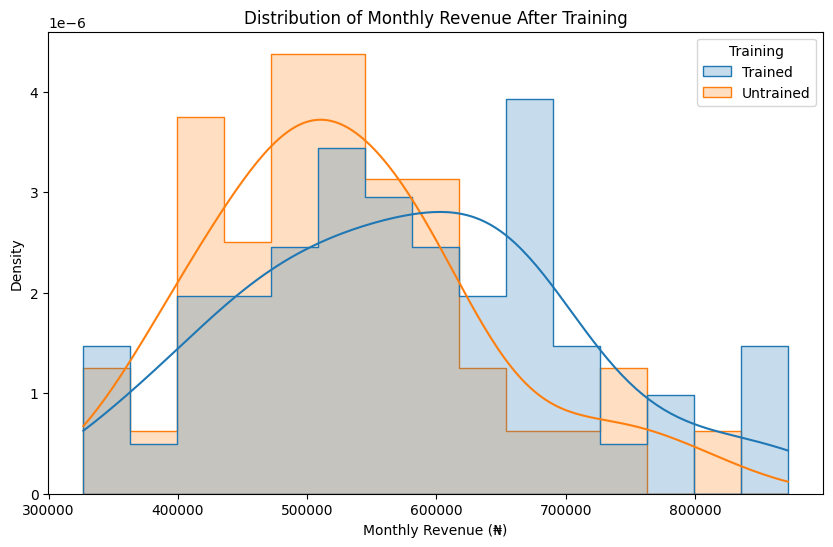

In [5]:

# STEP 8: REVENUE DISTRIBUTION

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Revenue_After",
    hue="Training",
    kde=True,
    bins=15,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Monthly Revenue After Training")
plt.xlabel("Monthly Revenue (₦)")
plt.ylabel("Density")

plt.show()


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Plotting libraries imported successfully.")

Plotting libraries imported successfully.


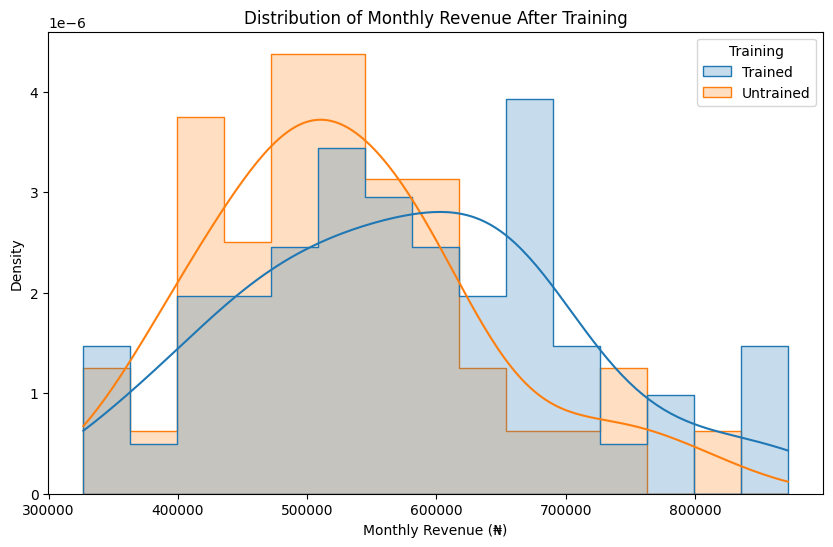

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Revenue_After",
    hue="Training",
    kde=True,
    bins=15,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Monthly Revenue After Training")
plt.xlabel("Monthly Revenue (₦)")
plt.ylabel("Density")
plt.show()

In [9]:
df["Revenue_Change"] = (
    df["Revenue_After"] - df["Revenue_Before"]
)

print("REVENUE CHANGE SUMMARY")
print(df["Revenue_Change"].describe().round(2))

print("\nAVERAGE REVENUE CHANGE BY TRAINING GROUP")
display(
    df.groupby("Training")["Revenue_Change"]
    .agg(["count", "mean", "std", "median"])
    .round(2)
)

REVENUE CHANGE SUMMARY
count       100.00
mean      56181.14
std       84760.43
min     -206888.72
25%        -859.71
50%       55700.79
75%      108315.97
max      349691.20
Name: Revenue_Change, dtype: float64

AVERAGE REVENUE CHANGE BY TRAINING GROUP


,count,mean,std,median
Training,,,,
Trained,56,88293.14,77058.03,86825.72
Untrained,44,15311.34,76769.21,22395.46


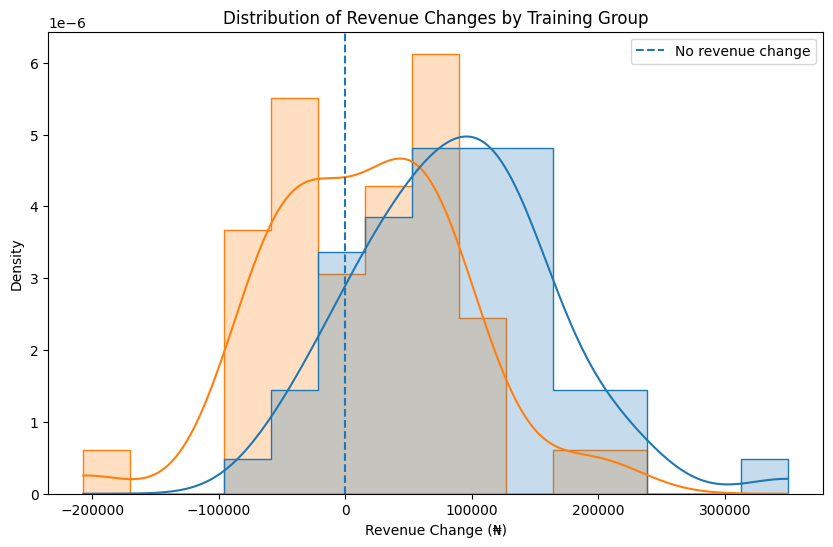

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Revenue_Change",
    hue="Training",
    kde=True,
    bins=15,
    element="step",
    stat="density",
    common_norm=False
)

plt.axvline(0, linestyle="--", label="No revenue change")

plt.title("Distribution of Revenue Changes by Training Group")
plt.xlabel("Revenue Change (₦)")
plt.ylabel("Density")
plt.legend()
plt.show()

In [12]:
mean_revenue = df["Revenue_After"].mean()

standard_error = stats.sem(df["Revenue_After"])

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(df) - 1,
    loc=mean_revenue,
    scale=standard_error
)

print("95% CONFIDENCE INTERVAL FOR MEAN REVENUE")
print(f"Sample mean: ₦{mean_revenue:,.2f}")
print(f"Lower bound: ₦{confidence_interval[0]:,.2f}")
print(f"Upper bound: ₦{confidence_interval[1]:,.2f}")

95% CONFIDENCE INTERVAL FOR MEAN REVENUE
Sample mean: ₦556,073.11
Lower bound: ₦532,235.88
Upper bound: ₦579,910.33


In [13]:
trained = df.loc[
    df["Training"] == "Trained", "Revenue_After"
]

untrained = df.loc[
    df["Training"] == "Untrained", "Revenue_After"
]

t_statistic, p_value = stats.ttest_ind(
    trained,
    untrained,
    equal_var=False
)

print("WELCH INDEPENDENT-SAMPLES T-TEST")
print(f"Trained mean: ₦{trained.mean():,.2f}")
print(f"Untrained mean: ₦{untrained.mean():,.2f}")
print(f"Mean difference: ₦{trained.mean() - untrained.mean():,.2f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

WELCH INDEPENDENT-SAMPLES T-TEST
Trained mean: ₦576,829.28
Untrained mean: ₦529,656.17
Mean difference: ₦47,173.11
T-statistic: 2.0206
P-value: 0.046061
Decision: Reject the null hypothesis.


In [14]:
contingency_table = pd.crosstab(
    df["Sector"],
    df["Training"]
)

print("CONTINGENCY TABLE")
display(contingency_table)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("\nCHI-SQUARE TEST OF INDEPENDENCE")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

print("\nEXPECTED FREQUENCIES")
display(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)

CONTINGENCY TABLE


Training,Trained,Untrained
Sector,,
Agriculture,9,11
Manufacturing,16,8
Retail,12,14
Services,19,11



CHI-SQUARE TEST OF INDEPENDENCE
Chi-square statistic: 3.7681
Degrees of freedom: 3
P-value: 0.287618

EXPECTED FREQUENCIES


Training,Trained,Untrained
Sector,,
Agriculture,11.20,8.80
Manufacturing,13.44,10.56
Retail,14.56,11.44
Services,16.80,13.20


In [15]:
sector_groups = [
    group["Revenue_After"].values
    for sector, group in df.groupby("Sector")
]

anova_statistic, anova_p_value = stats.f_oneway(
    *sector_groups
)

print("ONE-WAY ANOVA: REVENUE BY BUSINESS SECTOR")

for sector, group in df.groupby("Sector"):
    print(
        f"{sector}: Mean = ₦{group['Revenue_After'].mean():,.2f}, "
        f"n = {len(group)}"
    )

print(f"\nF-statistic: {anova_statistic:.4f}")
print(f"P-value: {anova_p_value:.6f}")

if anova_p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

ONE-WAY ANOVA: REVENUE BY BUSINESS SECTOR
Agriculture: Mean = ₦601,111.64, n = 20
Manufacturing: Mean = ₦517,817.24, n = 24
Retail: Mean = ₦546,439.47, n = 26
Services: Mean = ₦565,001.27, n = 30

F-statistic: 1.9105
P-value: 0.133025
Decision: Fail to reject the null hypothesis.


In [16]:
levene_stat, levene_p = stats.levene(
    *sector_groups,
    center="median"
)

print("LEVENE'S TEST FOR HOMOGENEITY OF VARIANCES")
print(f"Test statistic: {levene_stat:.4f}")
print(f"P-value: {levene_p:.6f}")

if levene_p < 0.05:
    print("Decision: Evidence of unequal variances.")
else:
    print("Decision: Insufficient evidence of unequal variances.")

LEVENE'S TEST FOR HOMOGENEITY OF VARIANCES
Test statistic: 0.1598
P-value: 0.923106
Decision: Insufficient evidence of unequal variances.


In [17]:
df["ANOVA_Residual"] = (
    df["Revenue_After"]
    - df.groupby("Sector")["Revenue_After"].transform("mean")
)

shapiro_stat, shapiro_p = stats.shapiro(
    df["ANOVA_Residual"]
)

print("SHAPIRO-WILK NORMALITY TEST")
print(f"Test statistic: {shapiro_stat:.4f}")
print(f"P-value: {shapiro_p:.6f}")

if shapiro_p < 0.05:
    print("Decision: Evidence against normality.")
else:
    print("Decision: Insufficient evidence against normality.")

SHAPIRO-WILK NORMALITY TEST
Test statistic: 0.9780
P-value: 0.092826
Decision: Insufficient evidence against normality.


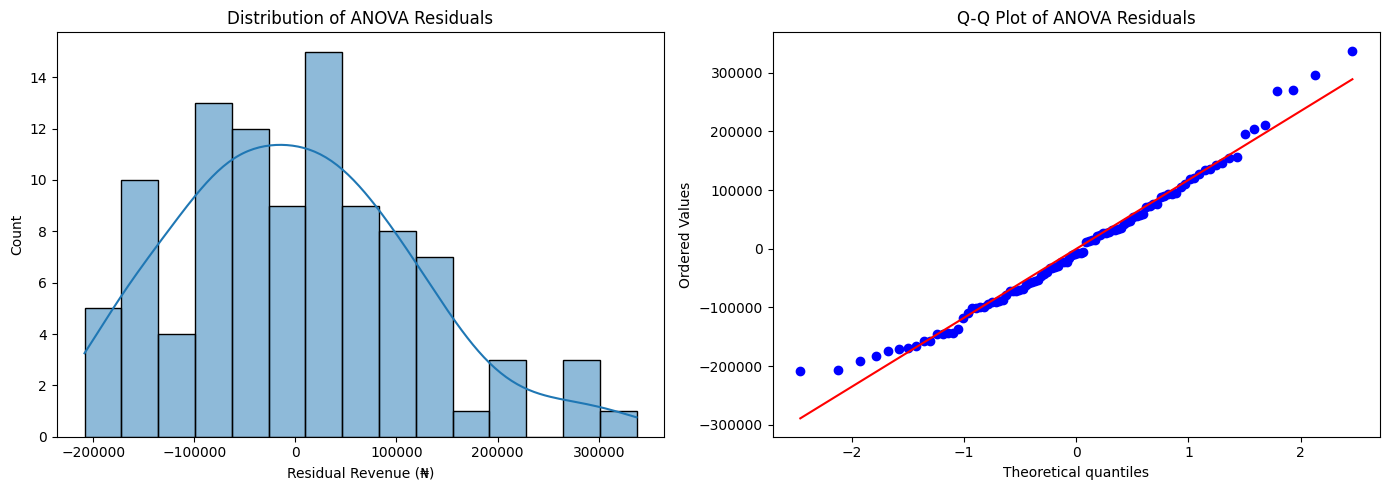

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["ANOVA_Residual"],
    kde=True,
    bins=15,
    ax=axes[0]
)

axes[0].set_title("Distribution of ANOVA Residuals")
axes[0].set_xlabel("Residual Revenue (₦)")

stats.probplot(
    df["ANOVA_Residual"],
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Q-Q Plot of ANOVA Residuals")

plt.tight_layout()
plt.show()

In [19]:
grand_mean = df["Revenue_After"].mean()

ss_between = sum(
    len(group) * (
        group["Revenue_After"].mean() - grand_mean
    )**2
    for _, group in df.groupby("Sector")
)

ss_total = sum(
    (df["Revenue_After"] - grand_mean)**2
)

eta_squared = ss_between / ss_total

print("ANOVA EFFECT SIZE")
print(f"Eta-squared: {eta_squared:.4f}")
print(f"Percentage of variation: {eta_squared * 100:.2f}%")

ANOVA EFFECT SIZE
Eta-squared: 0.0563
Percentage of variation: 5.63%


In [20]:
pooled_sd = np.sqrt(
    (
        (len(trained) - 1) * trained.var(ddof=1)
        + (len(untrained) - 1) * untrained.var(ddof=1)
    )
    / (len(trained) + len(untrained) - 2)
)

cohens_d = (
    trained.mean() - untrained.mean()
) / pooled_sd

print("COHEN'S D: TRAINING GROUP COMPARISON")
print(f"Pooled standard deviation: ₦{pooled_sd:,.2f}")
print(f"Cohen's d: {cohens_d:.4f}")

COHEN'S D: TRAINING GROUP COMPARISON
Pooled standard deviation: ₦118,406.00
Cohen's d: 0.3984


In [21]:
before = df["Revenue_Before"]
after = df["Revenue_After"]

paired_t, paired_p = stats.ttest_rel(after, before)

mean_change = (after - before).mean()

print("PAIRED T-TEST: BEFORE VS AFTER REVENUE")
print(f"Mean revenue before: ₦{before.mean():,.2f}")
print(f"Mean revenue after: ₦{after.mean():,.2f}")
print(f"Mean revenue change: ₦{mean_change:,.2f}")
print(f"Paired t-statistic: {paired_t:.4f}")
print(f"P-value: {paired_p:.6f}")

if paired_p < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

PAIRED T-TEST: BEFORE VS AFTER REVENUE
Mean revenue before: ₦499,891.96
Mean revenue after: ₦556,073.11
Mean revenue change: ₦56,181.14
Paired t-statistic: 6.6282
P-value: 0.000000
Decision: Reject the null hypothesis.


In [22]:
from scipy.stats import chi2_contingency

df["Positive_Revenue_Change"] = np.where(
    df["Revenue_Change"] > 0,
    "Positive",
    "Not Positive"
)

proportion_table = pd.crosstab(
    df["Training"],
    df["Positive_Revenue_Change"]
)

chi2, p_value, dof, expected = chi2_contingency(
    proportion_table
)

print("POSITIVE REVENUE CHANGE BY TRAINING GROUP")
display(proportion_table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

POSITIVE REVENUE CHANGE BY TRAINING GROUP


Positive_Revenue_Change,Not Positive,Positive
Training,,
Trained,7,49
Untrained,19,25


Chi-square statistic: 10.5139
Degrees of freedom: 1
P-value: 0.001185
Decision: Reject the null hypothesis.


In [23]:
n_total = proportion_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n_total * min(
            proportion_table.shape[0] - 1,
            proportion_table.shape[1] - 1
        )
    )
)

print("CHI-SQUARE EFFECT SIZE")
print(f"Cramer's V: {cramers_v:.4f}")

CHI-SQUARE EFFECT SIZE
Cramer's V: 0.3243


In [24]:
mean_diff = trained.mean() - untrained.mean()

se_diff = np.sqrt(
    trained.var(ddof=1) / len(trained)
    + untrained.var(ddof=1) / len(untrained)
)

df_welch = (
    trained.var(ddof=1) / len(trained)
    + untrained.var(ddof=1) / len(untrained)
)**2 / (
    (trained.var(ddof=1) / len(trained))**2 / (len(trained) - 1)
    + (untrained.var(ddof=1) / len(untrained))**2 / (len(untrained) - 1)
)

critical_t = stats.t.ppf(0.975, df_welch)

ci_lower = mean_diff - critical_t * se_diff
ci_upper = mean_diff + critical_t * se_diff

print("WELCH T-TEST: 95% CONFIDENCE INTERVAL")
print(f"Mean difference: ₦{mean_diff:,.2f}")
print(f"Degrees of freedom: {df_welch:.2f}")
print(f"95% CI lower: ₦{ci_lower:,.2f}")
print(f"95% CI upper: ₦{ci_upper:,.2f}")

WELCH T-TEST: 95% CONFIDENCE INTERVAL
Mean difference: ₦47,173.11
Degrees of freedom: 97.60
95% CI lower: ₦841.21
95% CI upper: ₦93,505.01


In [25]:
positive_rates = (
    df.groupby("Training")["Positive_Revenue_Change"]
    .apply(lambda x: (x == "Positive").mean() * 100)
)

print("FINAL PROJECT SUMMARY")
print("-" * 45)

print(f"Total SMEs: {len(df)}")
print(f"Trained SMEs: {(df['Training'] == 'Trained').sum()}")
print(f"Untrained SMEs: {(df['Training'] == 'Untrained').sum()}")

print("\nPOSITIVE REVENUE CHANGE")
print(f"Trained: {positive_rates['Trained']:.2f}%")
print(f"Untrained: {positive_rates['Untrained']:.2f}%")
print(
    f"Percentage-point difference: "
    f"{positive_rates['Trained'] - positive_rates['Untrained']:.2f}"
)

print("\nOVERALL REVENUE PERFORMANCE")
print(f"Mean revenue before: ₦{before.mean():,.2f}")
print(f"Mean revenue after: ₦{after.mean():,.2f}")
print(f"Mean revenue change: ₦{mean_change:,.2f}")

print("\nDATA LIMITATION")
print("Synthetic dataset; programmed group-level revenue increments.")
print("Findings demonstrate statistical methods, not causal evidence.")

FINAL PROJECT SUMMARY
---------------------------------------------
Total SMEs: 100
Trained SMEs: 56
Untrained SMEs: 44

POSITIVE REVENUE CHANGE
Trained: 87.50%
Untrained: 56.82%
Percentage-point difference: 30.68

OVERALL REVENUE PERFORMANCE
Mean revenue before: ₦499,891.96
Mean revenue after: ₦556,073.11
Mean revenue change: ₦56,181.14

DATA LIMITATION
Synthetic dataset; programmed group-level revenue increments.
Findings demonstrate statistical methods, not causal evidence.


# PROJECT 2: STATISTICAL INFERENCE AND HYPOTHESIS TESTING USING PYTHON

## 1. Executive Summary

This project investigates differences in revenue performance between trained and untrained small and medium-sized enterprises (SMEs), using a synthetic dataset of 100 businesses.

The analysis applies descriptive statistics, confidence interval estimation, independent and paired t-tests, chi-square tests of independence, one-way ANOVA, statistical diagnostics, and effect-size measures.

The principal findings are:

- Trained SMEs recorded an average revenue after the observation period of ₦576,829.28, compared with ₦529,656.17 for untrained SMEs.
- Welch's independent t-test identified a statistically significant difference in average revenue between the groups (t = 2.0206, p = 0.046061).
- The 95% confidence interval for the mean difference was ₦841.21 to ₦93,505.01.
- The proportion of SMEs experiencing positive revenue changes was 87.50% among trained businesses and 56.82% among untrained businesses.
- A chi-square test identified a statistically significant association between training participation and positive revenue change (χ² = 10.5139, p = 0.001185).
- One-way ANOVA did not identify statistically significant differences in average revenue across the four business sectors (F = 1.9105, p = 0.133025).

These findings demonstrate the application of statistical inference to business performance analysis. However, the dataset is synthetic, and its revenue-generation process deliberately assigns different revenue increments to trained and untrained SMEs. The results must therefore not be interpreted as empirical evidence that training causes higher revenue.

## 2. Research Background and Objectives

Business training is commonly used to improve the financial and operational performance of SMEs. However, evaluating differences in business outcomes requires more than comparing average values.

Statistical inference provides methods for determining whether observed differences are sufficiently large relative to sample variability to warrant further investigation.

The objectives of this project are to:

1. Examine the distribution of revenue before and after the observation period.
2. Compare average revenue performance between trained and untrained SMEs.
3. Estimate confidence intervals for relevant population means and group differences.
4. Evaluate whether revenue changes differ between training groups.
5. Investigate the association between business sector and training participation.
6. Compare revenue performance across business sectors.
7. Assess relevant statistical assumptions and quantify effect sizes.

## 3. Research Questions and Hypotheses

### Primary research question

Is there a statistically significant difference in average revenue after the observation period between trained and untrained SMEs?

- **Null hypothesis (H₀):** There is no difference in average revenue between trained and untrained SMEs.
- **Alternative hypothesis (H₁):** There is a difference in average revenue between trained and untrained SMEs.

### Additional research questions

**Question 2:** Did average revenue change between the before and after measurements?

- H₀: The mean paired revenue change is zero.
- H₁: The mean paired revenue change is not zero.

**Question 3:** Is training participation associated with positive revenue change?

- H₀: Training participation and positive revenue change are independent.
- H₁: Training participation and positive revenue change are associated.

**Question 4:** Does average revenue differ across business sectors?

- H₀: All four sector population means are equal.
- H₁: At least one sector population mean differs.

**Question 5:** Is business sector associated with training participation?

- H₀: Business sector and training participation are independent.
- H₁: Business sector and training participation are associated.

The significance level for hypothesis testing is α = 0.05.

## 4. Dataset Description

The analysis uses a synthetically generated dataset containing 100 SME observations.

| Variable | Description |
|---|---|
| SME_ID | Unique business identifier |
| Sector | Agriculture, Retail, Manufacturing, or Services |
| Training | Trained or Untrained |
| Revenue_Before | Revenue before the observation period |
| Revenue_After | Revenue after the observation period |
| Revenue_Change | Difference between after and before revenue |
| Positive_Revenue_Change | Whether revenue change was positive |

### Sample composition

| Category | Number |
|---|---:|
| Total SMEs | 100 |
| Trained | 56 |
| Untrained | 44 |
| Agriculture | 20 |
| Manufacturing | 24 |
| Retail | 26 |
| Services | 30 |

### Data quality assessment

The initial data quality checks identified:

- Missing values: 0
- Duplicate SME identifiers: 0
- Total observations: 100

The dataset was therefore complete with respect to the variables and duplicate checks performed.

## 5. Descriptive Statistical Analysis

### Revenue performance by training group

| Training group | Sample size | Mean revenue before | Mean revenue after |
|---|---:|---:|---:|
| Trained | 56 | ₦488,536.14 | ₦576,829.28 |
| Untrained | 44 | ₦514,344.83 | ₦529,656.17 |

The trained group had a lower average starting revenue but a higher average revenue after the observation period.

The average revenue change was:

| Training group | Mean revenue change | Median revenue change |
|---|---:|---:|
| Trained | ₦88,293.14 | ₦86,825.72 |
| Untrained | ₦15,311.34 | ₦22,395.46 |

The descriptive results indicate a larger average revenue increase among trained SMEs in the synthetic sample.

### Overall revenue performance

| Statistic | Revenue before | Revenue after |
|---|---:|---:|
| Mean | ₦499,891.96 | ₦556,073.11 |

The overall average revenue increased by ₦56,181.14.

### Confidence interval for overall mean revenue

The estimated mean revenue after the observation period was ₦556,073.11.

The 95% confidence interval was:

**₦532,235.88 to ₦579,910.33.**

This interval estimates the population mean under the applicable sampling assumptions. In frequentist terms, the 95% confidence level describes the long-run coverage of the interval procedure across repeated samples.

## 6. Independent Samples Welch t-Test

Welch's independent samples t-test was used to compare average revenue after the observation period between trained and untrained SMEs.

Welch's test was selected because it does not require the two groups to have equal population variances.

### Results

| Statistic | Result |
|---|---:|
| Trained group mean | ₦576,829.28 |
| Untrained group mean | ₦529,656.17 |
| Mean difference | ₦47,173.11 |
| t-statistic | 2.0206 |
| p-value | 0.046061 |
| Significance level | 0.05 |

### Decision

Since p = 0.046061 is below 0.05, the null hypothesis is rejected.

There is statistically significant evidence of a difference in average revenue between the two groups in this sample. The trained group has the higher observed average.

### 95% confidence interval for the mean difference

- Lower bound: ₦841.21
- Upper bound: ₦93,505.01
- Welch degrees of freedom: 97.60

The confidence interval excludes zero, which is consistent with the hypothesis-test decision.

However, its lower bound is close to zero, indicating considerable uncertainty about the magnitude of the difference.

### Effect size: Cohen's d

| Measure | Result |
|---|---:|
| Pooled standard deviation | ₦118,406.00 |
| Cohen's d | 0.3984 |

The standardised difference is approximately 0.40 pooled standard deviations, indicating a small-to-moderate effect under conventional Cohen benchmarks.

The p-value describes statistical evidence, while Cohen's d describes the standardised magnitude of the observed difference. They answer different questions.

## 7. Paired Samples t-Test

A paired t-test was conducted because revenue before and after the observation period was measured for the same SMEs.

### Results

| Statistic | Result |
|---|---:|
| Mean revenue before | ₦499,891.96 |
| Mean revenue after | ₦556,073.11 |
| Mean revenue change | ₦56,181.14 |
| Paired t-statistic | 6.6282 |
| p-value | Below 0.001 |

### Decision

The null hypothesis of zero mean paired revenue change is rejected.

The analysis provides strong statistical evidence that average revenue differed between the before and after measurements, with a positive observed change.

This result concerns the overall sample. It does not isolate the effect of training participation.

## 8. Chi-Square Test of Independence: Sector and Training

A chi-square test of independence was used to examine whether business sector was associated with training participation.

### Contingency table

| Sector | Trained | Untrained |
|---|---:|---:|
| Agriculture | 9 | 11 |
| Manufacturing | 16 | 8 |
| Retail | 12 | 14 |
| Services | 19 | 11 |

### Results

| Statistic | Result |
|---|---:|
| Chi-square statistic | 3.7681 |
| Degrees of freedom | 3 |
| p-value | 0.287618 |

All expected cell frequencies exceeded 5, satisfying the commonly used expected-frequency guideline for the Pearson chi-square approximation.

### Decision

Since p = 0.287618 exceeds 0.05, the null hypothesis is not rejected.

There is insufficient statistical evidence of an association between business sector and training participation in this sample.

This does not establish that the two variables are independent in the wider SME population.

## 9. One-Way ANOVA: Revenue Differences Across Sectors

A one-way analysis of variance was conducted to determine whether average revenue after the observation period differed across the four business sectors.

### Descriptive results

| Sector | Sample size | Mean revenue after |
|---|---:|---:|
| Agriculture | 20 | ₦601,111.64 |
| Manufacturing | 24 | ₦517,817.24 |
| Retail | 26 | ₦546,439.47 |
| Services | 30 | ₦565,001.27 |

### ANOVA results

| Statistic | Result |
|---|---:|
| F-statistic | 1.9105 |
| p-value | 0.133025 |
| Significance level | 0.05 |

### Decision

Since p = 0.133025 exceeds 0.05, the null hypothesis is not rejected.

The analysis does not provide sufficient evidence that mean revenue differs across the four sectors.

Although Agriculture has the highest observed mean and Manufacturing the lowest, these descriptive differences are not statistically significant at the selected significance level.

## 10. ANOVA Assumption Diagnostics

### Homogeneity of variance

Levene's test was applied to assess the equal-variance assumption.

| Statistic | Result |
|---|---:|
| Levene statistic | 0.1598 |
| p-value | 0.923106 |

The result does not provide evidence against the equal-variance assumption.

This does not prove that the sector variances are identical.

### Residual normality

The Shapiro-Wilk test was applied to the ANOVA residuals.

| Statistic | Result |
|---|---:|
| W-statistic | 0.9780 |
| p-value | 0.092826 |

Since the p-value exceeds 0.05, there is insufficient evidence to reject the residual-normality assumption.

The residual histogram and Q-Q plot showed approximate alignment with a normal distribution in the central region, with some deviation in the tails.

Taken together, the diagnostics did not identify a major violation of the assumptions examined. They do not establish perfect normality or equal variances.

## 11. ANOVA Effect Size: Eta-Squared

Eta-squared was calculated to quantify the proportion of observed revenue variation associated with differences between business sectors.

| Measure | Result |
|---|---:|
| Eta-squared | 0.0563 |
| Percentage of variation | 5.63% |

The result indicates that between-sector differences account for approximately 5.63% of the total observed revenue variation in the sample.

Using conventional Cohen-style benchmarks, this is a small effect, close to the commonly used medium-effect threshold of 0.06.

The effect-size estimate should be interpreted alongside the non-significant ANOVA result (p = 0.133025). It is not evidence that sector has a statistically established influence on revenue.

## 12. Chi-Square Test: Training and Positive Revenue Change

A second chi-square test examined whether training participation was associated with the occurrence of positive revenue change.

A positive revenue change was defined as Revenue_After greater than Revenue_Before.

### Contingency table

| Training group | Not positive | Positive | Total |
|---|---:|---:|---:|
| Trained | 7 | 49 | 56 |
| Untrained | 19 | 25 | 44 |
| Total | 26 | 74 | 100 |

### Positive revenue-change rates

| Training group | Positive revenue-change rate |
|---|---:|
| Trained | 87.50% |
| Untrained | 56.82% |

The difference between the two rates is 30.68 percentage points.

### Test results

| Statistic | Result |
|---|---:|
| Chi-square statistic | 10.5139 |
| Degrees of freedom | 1 |
| p-value | 0.001185 |

### Decision

The null hypothesis of independence is rejected.

The analysis provides statistically significant evidence of an association between training participation and positive revenue change in this synthetic sample.

### Effect size: Cramér's V

Cramér's V was calculated to measure the strength of association.

**Cramér's V = 0.3243.**

This indicates a moderate association under commonly used guidelines for a 2 × 2 contingency table.

The result complements the chi-square p-value: the test identifies statistical evidence of association, while Cramér's V describes its magnitude.

## 13. Consolidated Statistical Results

| Analysis | Test statistic | p-value / effect size | Decision or interpretation |
|---|---:|---:|---|
| Welch independent t-test | t = 2.0206 | p = 0.046061 | Significant difference |
| Welch mean-difference CI | — | ₦841.21–₦93,505.01 | Excludes zero |
| Cohen's d | — | 0.3984 | Small-to-moderate effect |
| Paired t-test | t = 6.6282 | p < 0.001 | Significant overall change |
| Sector-training chi-square | χ² = 3.7681 | p = 0.287618 | No significant association detected |
| Sector ANOVA | F = 1.9105 | p = 0.133025 | No significant sector difference detected |
| Eta-squared | — | 0.0563 | 5.63% of sample variation associated with sector |
| Training-positive-change chi-square | χ² = 10.5139 | p = 0.001185 | Significant association |
| Cramér's V | — | 0.3243 | Moderate association |

## 14. Limitations of the Analysis

Several limitations must be considered when interpreting the findings.

**1. Synthetic data**

The dataset was generated programmatically rather than collected from actual businesses. Its findings cannot be treated as empirical estimates of real SME performance.

**2. Deliberately programmed group increments**

The data-generation process assigned an ₦80,000 revenue increment to trained SMEs and an ₦20,000 increment to untrained SMEs, before adding random noise.

Consequently, the observed differences between training groups partly reflect the assumptions built into the simulation.

**3. No causal identification**

The analysis does not establish that training caused higher revenue. A real-world causal investigation would require an appropriate research design, such as random assignment or a defensible quasi-experimental approach.

**4. Limited sample size**

Although the dataset contains 100 observations, it is a relatively small simulated sample for broader business-sector conclusions.

**5. Potential omitted variables**

Real SME revenue performance may depend on business size, location, operating costs, access to credit, market conditions, management experience, and other factors not incorporated into this analysis.

**6. Model and test assumptions**

Statistical tests depend on assumptions concerning independence, distributional behaviour, and measurement. The diagnostics performed cover selected ANOVA assumptions but do not validate every assumption of every test.

## 15. Conclusion

This project demonstrates how Python-based statistical methods can be applied to investigate differences in business performance and relationships between categorical variables.

The analysis identified a statistically significant difference in average revenue after the observation period between trained and untrained SMEs. It also identified a statistically significant association between training participation and positive revenue change.

The paired t-test indicated a significant overall increase in average revenue, while the sector-based ANOVA did not identify statistically significant differences across the four business sectors.

The effect-size calculations added practical context to the hypothesis tests by quantifying the magnitude of observed differences and associations.

Overall, the project demonstrates the ability to prepare and inspect a dataset, formulate statistical hypotheses, select appropriate tests, evaluate assumptions, interpret p-values and confidence intervals, quantify effect sizes, and communicate limitations.

The findings are methodological demonstrations based on synthetic data. They should not be interpreted as evidence of real-world training effectiveness.

## 16. Technical Skills Demonstrated

- Python-based quantitative analysis.
- Pandas data manipulation and data quality assessment.
- NumPy numerical computation.
- SciPy statistical testing and inference.
- Matplotlib and Seaborn data visualisation.
- Descriptive and inferential statistics.
- Independent and paired samples hypothesis testing.
- Confidence interval estimation.
- Chi-square tests of independence.
- One-way ANOVA.
- Levene's and Shapiro-Wilk diagnostic tests.
- Residual analysis and Q-Q plots.
- Cohen's d, eta-squared, and Cramér's V.
- Statistical interpretation and technical reporting.

**Project status:** Core statistical analysis, hypothesis testing, assumption diagnostics, effect-size calculations, and final report completed.

**Dataset classification:** Synthetic educational dataset.

**Reproducibility:** Python notebook with a fixed random seed (`np.random.seed(42)`).